### Imports

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import create_dataset, IMG_SIZE, BATCH_SIZE

print("TensorFlow version:", tf.__version__)
print("Project root:", PROJECT_ROOT)

TensorFlow version: 2.21.0
Project root: d:\Coding Files\PlantDiseaseDetection


### Define paths and classes

In [3]:
DATA_PATH = PROJECT_ROOT / "dataset" / "processed"
MODEL_PATH = PROJECT_ROOT / "models"
GRAPH_PATH = PROJECT_ROOT / "results" / "graphs"

MODEL_PATH.mkdir(parents=True, exist_ok=True)
GRAPH_PATH.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_healthy"
]

NUM_CLASSES = len(CLASSES)

print("Number of classes:", NUM_CLASSES)

Number of classes: 5


### Load CSV files

In [4]:
train_df = pd.read_csv(DATA_PATH / "train.csv")
validation_df = pd.read_csv(DATA_PATH / "validation.csv")
test_df = pd.read_csv(DATA_PATH / "test.csv")

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Testing images:", len(test_df))

Training images: 5305
Validation images: 1137
Testing images: 1137


### Create TensorFlow datasets

In [5]:
train_dataset = create_dataset(
    train_df,
    CLASSES,
    training=True
)

validation_dataset = create_dataset(
    validation_df,
    CLASSES,
    training=False
)

test_dataset = create_dataset(
    test_df,
    CLASSES,
    training=False
)
print("Training dataset:", train_dataset)
print("Validation dataset:", validation_dataset)
print("Testing dataset:", test_dataset)

Training dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Validation dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Testing dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


### Define the model

In [6]:
from tensorflow.keras import layers, models

model = models.Sequential([
    # Input layer
    layers.Input(shape=(224, 224, 3)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Feature extraction
    layers.GlobalAveragePooling2D(),

    # Classification layers
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,301 (434.77 KB)

 Trainable params: 110,853 (433.02 KB)

 Non-trainable params: 448 (1.75 KB)

### Compile the model
##### Configure training

In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Configure callbacks
#### Callbacks help us manage training automatically.

In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH / "custom_cnn.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

### Start training

In [9]:
EPOCHS = 15

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 209s 604ms/step - accuracy: 0.7470 - loss: 0.6760 - val_accuracy: 0.3923 - val_loss: 2.7540 - learning_rate: 0.0010
Epoch 2/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 189s 565ms/step - accuracy: 0.8319 - loss: 0.4487 - val_accuracy: 0.7696 - val_loss: 0.6957 - learning_rate: 0.0010
Epoch 3/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 189s 565ms/step - accuracy: 0.8675 - loss: 0.3637 - val_accuracy: 0.7581 - val_loss: 0.6606 - learning_rate: 0.0010
Epoch 4/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 185s 554ms/step - accuracy: 0.8771 - loss: 0.3329 - val_accuracy: 0.3351 - val_loss: 3.0283 - learning_rate: 0.0010
Epoch 5/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 190s 569ms/step - accuracy: 0.8888 - loss: 0.3140 - val_accuracy: 0.5198 - val_loss: 2.1553 - learning_rate: 0.0010
Epoch 6/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 189s 565ms/step - accuracy: 0.9237 - loss: 0.2307 - val_accuracy: 0.6412 - val_loss: 1.4352 - learning_rate: 5.0000e-04
Epoch 7/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 188s 564ms/step - ac

### Visualize training performance

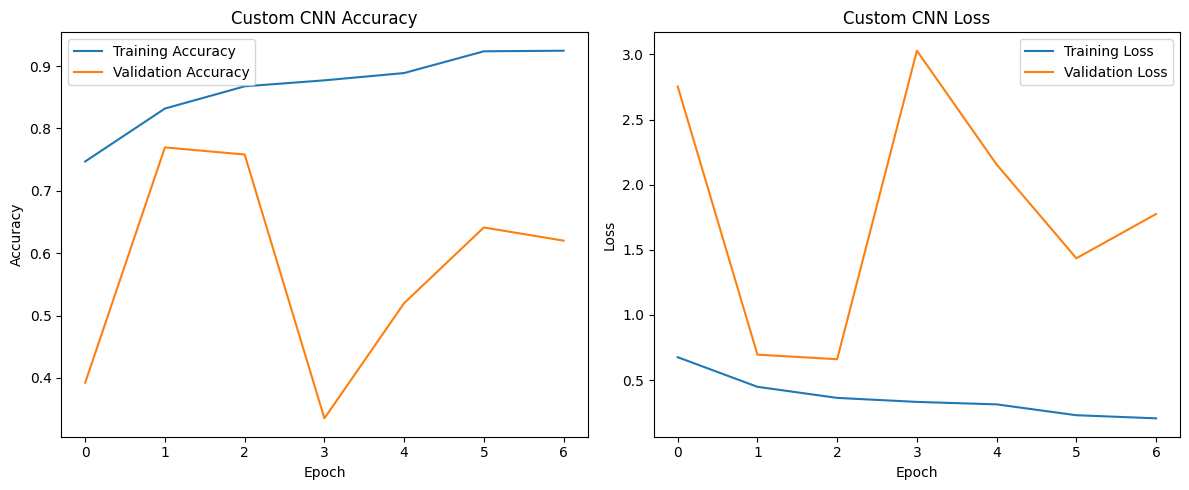

In [10]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Custom CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Custom CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "custom_cnn_training.png",
    dpi=300
)

plt.show()

### Test accuracy and loss

In [11]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

72/72 ━━━━━━━━━━━━━━━━━━━━ 13s 177ms/step - accuracy: 0.7590 - loss: 0.6435
Test Loss: 0.6435077786445618
Test Accuracy: 75.90149641036987 %


### Generate classification metrics

In [12]:
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=[
            name.replace("Tomato___", "")
            for name in CLASSES
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

Tomato_Bacterial_spot       0.99      0.65      0.78       319
  Tomato_Early_blight       0.68      0.65      0.66       150
   Tomato_Late_blight       0.86      0.67      0.75       287
     Tomato_Leaf_Mold       0.60      0.89      0.72       143
       Tomato_healthy       0.68      1.00      0.81       238

             accuracy                           0.76      1137
            macro avg       0.76      0.77      0.75      1137
         weighted avg       0.80      0.76      0.76      1137



### Generate the confusion matrix

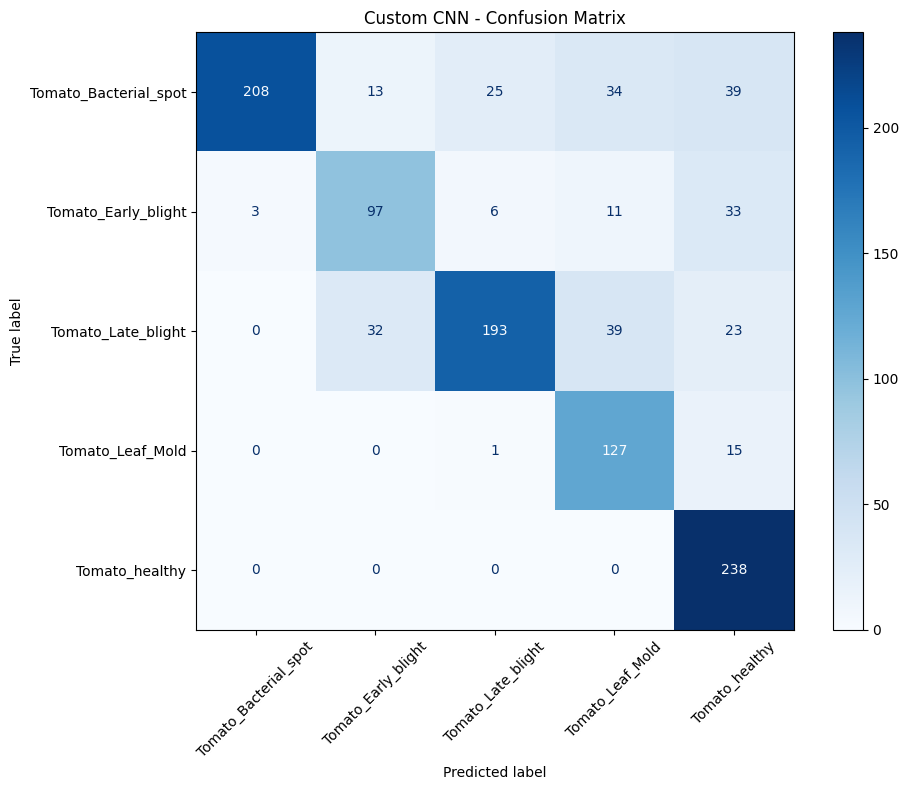

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        name.replace("Tomato___", "")
        for name in CLASSES
    ]
)

fig, ax = plt.subplots(figsize=(10, 8))

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Custom CNN - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "results" / "confusion_matrix.png",
    dpi=300
)

plt.show()

### Save your trained model

In [14]:
model.save(MODEL_PATH / "custom_cnn.keras")

print("Custom CNN model saved successfully!")

Custom CNN model saved successfully!
